### Exo view at 8 FPS vs ego at 1 FPS

`why_concepts.ipynb` found that every way of supervising zero-shot Qwen3.5-4B **ego 1 FPS** video (labels, why-CCA,
why concepts) reached the same ceiling, about 0.43 accuracy and 0.35 within-scenario Spearman, and that the concepts the
video could not see were mostly about timing (Dance rhythm, Music tempo) or detail (Cooking knife work). Here the
video changes instead of the supervision:

* **exo 8 FPS**: the take's best exo camera (Ego-Exo4D `best_exo`; exo1 for the 80 takes without one), 20-frame
  windows at 8 FPS (2.5 s each), spread evenly over the take, about one per 10 s and at least 3 (~25% of the take);
* **exo 1 FPS** (control): the same camera in back-to-back 20-frame 1 FPS tiles, exactly the ego design, so that
  ego vs exo 1 FPS isolates the view and exo 1 FPS vs exo 8 FPS isolates the frame rate (with its shorter coverage);
* **ego 1 FPS**: the tiles used so far.

Exo frames are scaled to 576x320 (the 448x448 ego pixel budget, as in `view_comparison.ipynb`); every window has
20 frames, so all three sources cost the same per window. Each take = mean of its window embeddings (layers 8 / 16 / 32).

Evaluation as in `why_concepts.ipynb`: the same 4 x 5-fold CV split by participant over all 1,338 takes; per source
and layer the full features, label PLS and the concept bottleneck; 4-class accuracy and the ordinal within-scenario
Spearman (ridge regression, predictions centered within each fold and scenario); scenario-only and duration-only
controls; participant-bootstrap intervals; and which why concepts each source can predict.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


In [2]:
# Every expert's rating and why for each take.
def take_whys(take):
    whys = []
    for path in sorted((COMMENTARY_ROOT / take).glob("*/data.json")):
        proficiency = json.loads(path.read_text(encoding="utf-8")).get("proficiency") or {}
        why = (proficiency.get("why") or "").strip()
        if not why:
            continue
        try:
            rating = float(proficiency.get("rating"))
        except (TypeError, ValueError):
            rating = None
        whys.append({"expert": path.parent.name, "why": why, "rating": rating})
    return whys

pairs = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        for w in take_whys(clip["take_name"]):
            rated = f"Rating {w['rating']:g}/10: {w['why']}" if w["rating"] is not None else w["why"]
            pairs.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                          "participant": clip["participant"], "score": clip["score"], "rating": w["rating"],
                          "rated": rated, "plain": w["why"]})
for split in ("train", "test"):
    split_pairs = [p for p in pairs if p["split"] == split]
    print(f"{split}: {len(split_pairs)} whys over {len({p['take_name'] for p in split_pairs})} of "
          f"{len(clips_by_split[split])} takes; {sum(p['rating'] is None for p in split_pairs)} without a rating")

train: 4344 whys over 1174 of 1174 takes; 83 without a rating
test: 660 whys over 164 of 164 takes; 11 without a rating


In [3]:
# Concept vocabulary for proficiency.why, drafted from a reading of training whys only.
ACTIVITY = {"Basketball": "basketball", "Cooking": "cooking", "Dance": "dance", "Music": "music (playing an instrument)",
            "Rock Climbing": "bouldering (rock climbing)", "Soccer": "soccer"}

GENERIC = {
    "fluency": "flow and continuity (executing smoothly without stopping, hesitating or getting stuck)",
    "control": "control, balance and precision of movement",
    "technique": "technique and form",
    "pace": "speed, pace and efficiency",
    "confidence": "confidence and comfort with the task",
    "knowledge": "knowledge of the task (knowing the steps, rules, choreography, route or piece)",
    "outcome": "success of the outcome (made shots, finished route, correct notes, good final dish)",
    "power": "power, energy and athleticism",
}

SPECIFIC = {
    "Basketball": {
        "footwork": "footwork and steps into the shot",
        "shooting form": "shooting form and release (release point, follow-through, hand placement)",
        "ball handling": "ball handling and dribbling",
        "lift": "lift and explosiveness",
        "weak hand": "use of the weaker hand",
    },
    "Cooking": {
        "knife skills": "knife skills",
        "heat control": "heat and temperature control",
        "workspace": "organization and cleanliness of the workspace (mise en place)",
        "recipe steps": "following the recipe and the order of steps",
        "food result": "quality of the finished food (doneness, texture, taste)",
        "safety": "kitchen safety and hygiene",
    },
    "Dance": {
        "rhythm": "rhythm and musicality (staying on the beat)",
        "memory": "memory of the choreography",
        "arms": "use of the arms and upper body",
        "grounding": "balance and grounding",
        "dynamics": "energy, dynamics and sharpness of movement",
        "clarity": "clarity and precision of the steps",
    },
    "Music": {
        "pitch": "pitch accuracy and intonation (correct notes)",
        "tempo": "rhythm and steadiness of tempo",
        "tone": "tone quality and articulation",
        "musicality": "musicality, phrasing and expression",
        "hand position": "hand position and posture",
    },
    "Rock Climbing": {
        "progress": "progress on the route (how far they got, whether they sent it)",
        "footwork": "footwork and foot placement",
        "tension": "body tension (keeping the feet on the wall)",
        "hips": "hip and body positioning",
        "energy use": "efficient use of strength (not over-relying on the arms)",
        "dynamic moves": "dynamic moves and momentum",
        "route reading": "route reading and decision making",
    },
    "Soccer": {
        "ball control": "ball control and touch",
        "weak foot": "use of the weaker foot",
        "striking": "striking technique and shot accuracy",
        "agility": "speed and change of direction",
        "posture": "body posture and balance over the ball",
    },
}

def concepts_for(scenario):
    return {**GENERIC, **SPECIFIC[scenario]}

ANSWERS = ["good", "mixed", "poor", "unmentioned"]

def concept_prompt(scenario, why, description):
    return (f"Here is an expert's feedback on a person's {ACTIVITY[scenario]} performance:\n\n\"{why}\"\n\n"
            f"According to this feedback, how was the person's {description}? "
            f"Reply with exactly one word: good, mixed, poor, or unmentioned.")


COLUMNS = [("all", c) for c in GENERIC] + [(s, c) for s in SPECIFIC for c in SPECIFIC[s]]
COLUMN = {key: i for i, key in enumerate(COLUMNS)}

In [4]:
import math
from concurrent.futures import ThreadPoolExecutor

import torch
from tqdm.auto import tqdm

# Exo video of every take, zero-shot Qwen3.5-4B, two samplings from one decoding pass:
#   * 1 FPS tiles: back-to-back 20-frame windows covering the take, exactly the ego design (view changes, nothing else);
#   * 8 FPS windows: 20 frames (2.5 s) each, spread evenly over the take, one per ~10 s and at least 3.
# Frames are scaled to 576x320 (320x576 for portrait cameras) during decoding: the 448x448 ego pixel budget, as in
# view_comparison.ipynb. Each window is the video alone, pooled over its video tokens at layers 8 / 16 / 32.
EMBEDDING_DIR = Path("embeddings")
LAYERS = {"early": 8, "middle": 16, "last": 32}
EXO_SIZE = (576, 320)
WINDOW_FRAMES = 20
DENSE_FPS, DENSE_SPACING_S, MIN_DENSE_WINDOWS = 8, 10, 3
BATCH_WINDOWS = 4

TAKES_META = {t["take_name"]: t for t in json.loads((DATA_ROOT / "takes.json").read_text(encoding="utf-8"))}
EXO1_PATH = {}
for annotation_file in ("proficiency_demonstrator_train.json", "proficiency_demonstrator_val.json"):
    for m in json.loads((ANNOTATION_ROOT / annotation_file).read_text(encoding="utf-8"))["annotations"]:
        parts = m["video_paths"]["exo1"].split("/")
        parts[-1:-1] = ["downscaled", "448"]
        EXO1_PATH[take_name(m)] = DATA_ROOT.joinpath(*parts)

def exo_camera(take):
    """The take's best exo camera per Ego-Exo4D (takes.json best_exo); exo1 when it has none."""
    best = TAKES_META[take].get("best_exo")
    path = DATA_ROOT / "takes" / take / "frame_aligned_videos" / "downscaled" / "448" / f"{best}.mp4"
    if best and path.exists():
        return best, path
    return "exo1 (no best_exo)", EXO1_PATH[take]

def tile_windows(take, length=WINDOW_FRAMES):
    """Back-to-back windows covering the take (as for ego); a last partial window (made even) is kept only if it is
    at least half a window long, or if it is the only one."""
    seconds = clip_of[take]["seconds"]
    windows = []
    for start in range(0, seconds, length):
        size = min(length, seconds - start)
        size -= size % 2
        if size >= 2 and (size >= length // 2 or not windows):
            windows.append((start, size))
    return windows

def dense_starts(num_dense_frames):
    count = max(MIN_DENSE_WINDOWS, math.ceil(num_dense_frames / DENSE_FPS / DENSE_SPACING_S))
    return sorted(set(np.round(np.linspace(0, num_dense_frames - WINDOW_FRAMES, count)).astype(int).tolist()))

def decode_exo(take):
    """{"camera", "sparse": (seconds, H, W, 3) 1 FPS frames, "dense": {start: (20, H, W, 3)} 8 FPS windows}."""
    camera, path = exo_camera(take)
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        stream.thread_type = "AUTO"
        rate, total = float(stream.average_rate), stream.frames
        width, height = stream.codec_context.width, stream.codec_context.height
        W, H = EXO_SIZE if width >= height else EXO_SIZE[::-1]
        starts = dense_starts(int((total - 1) * DENSE_FPS / rate) + 1)
        wanted = {int(math.floor(k * rate / DENSE_FPS + 0.5)): k for s in starts for k in range(s, s + WINDOW_FRAMES)}
        step = round(rate / WINDOW_FPS)
        sparse, dense = [], {}
        for i, frame in enumerate(container.decode(video=0)):
            k = wanted.get(i)
            if i % step == 0 or k is not None:
                array = frame.to_ndarray(format="rgb24", width=W, height=H, interpolation="BILINEAR")
                if i % step == 0:
                    sparse.append(array)
                if k is not None:
                    dense[k] = array
    windows = {s: np.stack([dense[k] for k in range(s, s + WINDOW_FRAMES)]) for s in starts
               if all(k in dense for k in range(s, s + WINDOW_FRAMES))}
    return {"camera": camera, "sparse": np.stack(sparse), "dense": windows}

def load_cache(path):
    return torch.load(path) if path.exists() else {"camera": {}, "windows": {}}

TILE_CACHE = EMBEDDING_DIR / "qwen35_base_exo_tiles1fps.pt"
DENSE_CACHE = EMBEDDING_DIR / "qwen35_base_exo_dense8fps.pt"
tile_cache, dense_cache = load_cache(TILE_CACHE), load_cache(DENSE_CACHE)
todo = [t for t in clip_of if t not in tile_cache["windows"] or t not in dense_cache["windows"]]
print(f"{len(clip_of) - len(todo)} takes already embedded, {len(todo)} to go")

if todo:
    from transformers import AutoModelForMultimodalLM, AutoProcessor, BitsAndBytesConfig
    from transformers.video_utils import VideoMetadata

    model_id = "Qwen/Qwen3.5-4B"
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16,
                                    bnb_4bit_use_double_quant=True)
    model = AutoModelForMultimodalLM.from_pretrained(model_id, quantization_config=bnb_config, device_map="auto").eval()
    processor = AutoProcessor.from_pretrained(model_id)
    processor.video_processor.cap_pixels_per_frame = False  # frames arrive at 576x320 and stay so
    VIDEO_TOKEN_ID = processor.tokenizer.convert_tokens_to_ids("<|video_pad|>")
    VIDEO_PROMPT = processor.apply_chat_template([{"role": "user", "content": [{"type": "video"}]}], tokenize=False)
    DECODER_LAYERS = [m for m in model.modules() if type(m).__name__ == "Qwen3_5DecoderLayer"]
    _pool_mask, _pooled = None, {}

    def _make_pool_hook(layer):
        def hook(module, args, output):
            if _pool_mask is None:
                return
            hidden = output[0] if isinstance(output, tuple) else output
            mask = _pool_mask.unsqueeze(-1).float()
            _pooled[layer] = ((hidden.float() * mask).sum(1) / mask.sum(1)).cpu()
        return hook

    for layer in LAYERS.values():
        DECODER_LAYERS[layer - 1].register_forward_hook(_make_pool_hook(layer))

    @torch.inference_mode()
    def layer_means(batch, mask):
        global _pool_mask
        _pool_mask = mask.to(model.device)
        _pooled.clear()
        try:
            with torch.autocast("cuda", dtype=torch.bfloat16):
                model(**batch.to(model.device), logits_to_keep=1)
        finally:
            _pool_mask = None
        return torch.stack([_pooled[layer] for layer in LAYERS.values()], 1)

    def embed(windows, fps):
        """(n, len(LAYERS), hidden) for equal-length windows sampled at fps; timestamps relative to each window."""
        length, step = len(windows[0]), 30.0 / fps
        metadata = VideoMetadata(total_num_frames=int(round(length * step)), fps=30.0,
                                 frames_indices=np.floor(np.arange(length) * step + 0.5).astype(int))
        out = []
        for i in range(0, len(windows), BATCH_WINDOWS):
            chunk = windows[i:i + BATCH_WINDOWS]
            batch = processor(text=[VIDEO_PROMPT] * len(chunk), videos=chunk, video_metadata=[metadata] * len(chunk),
                              do_sample_frames=False, return_tensors="pt")
            grid = batch["video_grid_thw"]
            assert (grid[:, 0] == length // 2).all() and all(sorted(g[1:].tolist()) == [20, 36] for g in grid), grid
            out.append(layer_means(batch, batch["input_ids"] == VIDEO_TOKEN_ID))
        return torch.cat(out)

    with ThreadPoolExecutor(1) as pool:
        upcoming = pool.submit(decode_exo, todo[0])
        for k, take in enumerate(tqdm(todo, desc="exo takes"), 1):
            decoded = upcoming.result()
            if k < len(todo):
                upcoming = pool.submit(decode_exo, todo[k])
            sparse = decoded["sparse"]
            assert len(sparse) >= clip_of[take]["seconds"] - 1, (take, len(sparse), clip_of[take]["seconds"])
            tiles = {}
            by_length = defaultdict(list)
            for start, size in tile_windows(take):
                if start + size <= len(sparse):
                    by_length[size].append(start)
            for size, starts in by_length.items():
                for start, e in zip(starts, embed([sparse[s:s + size] for s in starts], WINDOW_FPS)):
                    tiles[start, size] = e
            starts = sorted(decoded["dense"])
            dense = dict(zip(starts, embed([decoded["dense"][s] for s in starts], DENSE_FPS)))
            for cache, windows in ((tile_cache, tiles), (dense_cache, dense)):
                cache["windows"][take], cache["camera"][take] = windows, decoded["camera"]
            if k % 25 == 0 or k == len(todo):
                torch.save(tile_cache, TILE_CACHE)
                torch.save(dense_cache, DENSE_CACHE)
    del model
    torch.cuda.empty_cache()

print("cameras:", Counter(tile_cache["camera"].values()).most_common())
print(f"{sum(map(len, tile_cache['windows'].values()))} exo 1 FPS tiles, "
      f"{sum(map(len, dense_cache['windows'].values()))} exo 8 FPS windows over {len(dense_cache['windows'])} takes")

1338 takes already embedded, 0 to go
cameras: [('cam03', 418), ('cam01', 341), ('cam02', 253), ('cam04', 116), ('exo1 (no best_exo)', 80), ('gp01', 45), ('gp03', 34), ('cam05', 22), ('gp04', 11), ('gp05', 9), ('gp02', 9)]
7486 exo 1 FPS tiles, 15662 exo 8 FPS windows over 1338 takes


In [5]:
from scipy.stats import spearmanr

# Concept labels from why_concepts.ipynb (cached), as take-level scores.
concept_cache = torch.load(EMBEDDING_DIR / "qwen35_why_concepts.pt")
all_clips = clips_by_split["train"] + clips_by_split["test"]
names = [c["take_name"] for c in all_clips]
position = {name: i for i, name in enumerate(names)}
scores = np.array([c["score"] for c in all_clips])
scenarios = np.array([c["scenario"] for c in all_clips])
participants = np.array([c["participant"] for c in all_clips])
original_test = np.array([c["take_name"] in {t["take_name"] for t in clips_by_split["test"]} for c in all_clips])
SCENARIO_NAMES = np.unique(scenarios)

def why_vectors(pair):
    probabilities = concept_cache["scores"][pair["scenario"], pair["plain"]].numpy()
    signed, mention = np.full(len(COLUMNS), np.nan), np.full(len(COLUMNS), np.nan)
    for i, name in enumerate(concepts_for(pair["scenario"])):
        column = COLUMN["all", name] if name in GENERIC else COLUMN[pair["scenario"], name]
        signed[column] = probabilities[i, 0] - probabilities[i, 2]
        mention[column] = 1 - probabilities[i, 3]
    return signed, mention

pair_take = np.array([position[p["take_name"]] for p in pairs])
pair_signed, _ = map(np.array, zip(*[why_vectors(p) for p in pairs]))
pair_rating = np.array([np.nan if p["rating"] is None else p["rating"] for p in pairs])
applicable = np.array([[s in ("all", scenario) for s, _ in COLUMNS] for scenario in scenarios])
take_signed = np.stack([np.nanmean(pair_signed[pair_take == t], 0) for t in range(len(names))])
take_signed[~applicable] = 0
take_rating = np.array([np.nanmean(pair_rating[pair_take == t]) if (~np.isnan(pair_rating[pair_take == t])).any()
                        else np.nan for t in range(len(names))])

def scenario_centered(values, rows):
    out = values.astype(float).copy()
    for s in np.unique(scenarios[rows]):
        r = rows & (scenarios == s)
        out[r] -= np.nanmean(values[r])
    return out

# Video sources: each take = mean of its window embeddings.
ego_cache = torch.load(EMBEDDING_DIR / "qwen35_base_goodtip_windows.pt")
SOURCES = {
    "ego 1 FPS": {t: torch.stack([ego_cache[t][w] for w in tile_windows(t)]) for t in names},
    "exo 1 FPS": {t: torch.stack(list(tile_cache["windows"][t].values())) for t in names},
    "exo 8 FPS": {t: torch.stack(list(dense_cache["windows"][t].values())) for t in names},
}
del ego_cache
video = {(source, layer): np.stack([windows[t][:, i].double().mean(0).numpy() for t in names])
         for source, windows in SOURCES.items() for i, layer in enumerate(LAYERS.values())}
log_duration = np.log([clip_of[t]["seconds"] for t in names])
print(f"{len(names)} takes, {len(set(participants))} participants")
seen_seconds = {"ego 1 FPS": sum(size for t in names for _, size in tile_windows(t)),
                "exo 1 FPS": sum(size for t in names for _, size in tile_cache["windows"][t]),
                "exo 8 FPS": sum(len(dense_cache["windows"][t]) for t in names) * WINDOW_FRAMES / DENSE_FPS}
for source, windows in SOURCES.items():
    counts = np.array([len(windows[t]) for t in names])
    print(f"  {source:<10} {counts.sum():>6} windows, {np.median(counts):.0f} per take (median), "
          f"{seen_seconds[source] / 3600:.1f} h of video seen of {sum(clip_of[t]['seconds'] for t in names) / 3600:.1f} h")

C:\Users\darkn\AppData\Local\Temp\ipykernel_20416\1192086637.py:27: RuntimeWarning: Mean of empty slice
  take_signed = np.stack([np.nanmean(pair_signed[pair_take == t], 0) for t in range(len(names))])


1338 takes, 185 participants
  ego 1 FPS    7486 windows, 3 per take (median), 40.3 h of video seen of 41.2 h
  exo 1 FPS    7486 windows, 3 per take (median), 40.3 h of video seen of 41.2 h
  exo 8 FPS   15662 windows, 6 per take (median), 10.9 h of video seen of 41.2 h


In [6]:
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV, RidgeCV
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

N_REPEATS, N_FOLDS = 4, 5
PCA_DIMS, N_COMPONENTS = 64, 16
ALPHAS = np.logspace(-1, 5, 13)
CONCEPT_GROUPS = [([COLUMN["all", c] for c in GENERIC], np.ones(len(names), bool))] + \
                 [([COLUMN[s, c] for c in SPECIFIC[s]], scenarios == s) for s in SPECIFIC]
METHODS = ["full", "label PLS", "concept bottleneck"]

def centered(X, keys, fit):
    fit_rows = np.zeros(len(X), bool)
    fit_rows[fit] = True
    overall = X[fit_rows].mean(0)
    means = {k: X[fit_rows & (keys == k)].mean(0) if (fit_rows & (keys == k)).any() else overall for k in np.unique(keys)}
    return X - np.stack([means[k] for k in keys])

def project(x, mean, basis):
    return (x - mean) @ basis @ basis.T

def make_probe():
    return make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))

def predict_concepts(Z, train, target):
    out = np.zeros((len(target), len(COLUMNS)))
    for columns, rows in CONCEPT_GROUPS:
        fit_rows, target_rows = train[rows[train]], np.flatnonzero(rows[target])
        if len(fit_rows) < 10 or not len(target_rows):
            continue
        Y = centered(take_signed[:, columns], scenarios, fit_rows)
        ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS, alpha_per_target=True)).fit(Z[fit_rows], Y[fit_rows])
        out[np.ix_(target_rows, columns)] = ridge.predict(Z[target[target_rows]])
    return out

hits = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
predicted = defaultdict(lambda: np.zeros((N_REPEATS, len(names)), int))
continuous = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
concept_prediction = defaultdict(lambda: np.zeros((N_REPEATS, len(names), len(COLUMNS))))
fold_of = np.zeros((N_REPEATS, len(names)), int)

for repeat in range(N_REPEATS):  # same folds as why_cca_cv.ipynb and why_concepts.ipynb
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fold, (fit, held) in enumerate(tqdm(list(folds), desc=f"repeat {repeat + 1}")):
        fold_of[repeat, held] = fold
        onehot = OneHotEncoder(handle_unknown="ignore").fit(scenarios[fit][:, None]).transform(scenarios[:, None]).toarray()

        def run(key, features):
            X = np.hstack([onehot, features])
            prediction = make_probe().fit(X[fit], scores[fit]).predict(X[held])
            predicted[key][repeat, held] = prediction
            hits[key][repeat, held] = prediction == scores[held]
            ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 6, 17))).fit(X[fit], scores[fit])
            continuous[key][repeat, held] = ridge.predict(X[held])

        run("scenario only", np.zeros((len(names), 0)))
        duration = centered(log_duration[:, None], scenarios, fit)
        run("duration only", np.hstack([duration * (scenarios == s)[:, None] for s in SCENARIO_NAMES]))
        rating = np.where(np.isnan(take_rating), np.nanmean(take_rating[fit]), take_rating)
        Y_label = np.column_stack([np.eye(4)[scores[fit] - 1], rating[fit]])
        inner = list(GroupKFold(5).split(fit, groups=participants[fit]))
        for (source, layer), X_video in video.items():
            prefix = f"{source}, L{layer}"
            V = centered(X_video, scenarios, fit)
            pca_video = PCA(PCA_DIMS, svd_solver="full").fit(V[fit])
            mean, Z = pca_video.mean_, pca_video.transform(V)
            run(f"{prefix}: full", V)
            pls = PLSRegression(n_components=N_COMPONENTS, scale=True).fit(Z[fit], Y_label)
            basis = np.linalg.qr(pca_video.components_.T @ (pls.x_rotations_ / pls._x_std[:, None]))[0]
            run(f"{prefix}: label PLS", project(V, mean, basis))
            bottleneck = np.zeros((len(names), len(COLUMNS)))
            for a, b in inner:
                bottleneck[fit[b]] = predict_concepts(Z, fit[a], fit[b])
            bottleneck[held] = predict_concepts(Z, fit, held)
            concept_prediction[source, layer][repeat, held] = bottleneck[held]
            run(f"{prefix}: concept bottleneck", bottleneck)

assert all(not np.isnan(h).any() for h in hits.values())
print(f"{len(hits)} methods x {N_REPEATS} repeats x {len(names)} takes")

repeat 1:   0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


... (175 outputs left out)

C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


29 methods x 4 repeats x 1338 takes


In [7]:
from sklearn.metrics import balanced_accuracy_score

N_BOOTSTRAP = 1000
SOURCE_NAMES = list(SOURCES)
LAYER_LIST = list(LAYERS.values())
unique_participants = np.unique(participants)
rows_of = {p: np.flatnonzero(participants == p) for p in unique_participants}
boot = np.random.default_rng(0)
resamples = [np.concatenate([rows_of[p] for p in boot.choice(unique_participants, len(unique_participants))])
             for _ in range(N_BOOTSTRAP)]
SUBGROUPS = {"All": np.ones(len(names), bool), "Original test takes": original_test,
             "Rock Climbing": scenarios == "Rock Climbing"}
per_take = {key: h.mean(0) for key, h in hits.items()}
level_centered = scenario_centered(scores, np.ones(len(names), bool))

def within_fold_centered(c):
    """Removes each (repeat, fold, scenario) group's mean prediction (the fold's fitted scenario intercept is biased
    against its own held-out takes), then averages over repeats."""
    out = c.copy()
    for r in range(N_REPEATS):
        for fold in np.unique(fold_of[r]):
            for s in SCENARIO_NAMES:
                group = (fold_of[r] == fold) & (scenarios == s)
                if group.any():
                    out[r, group] -= c[r, group].mean()
    return out.mean(0)

ordinal = {key: within_fold_centered(c) for key, c in continuous.items()}

def rho(key, rows):
    a = ordinal[key][rows]
    return spearmanr(a, level_centered[rows])[0] if np.std(a) > 1e-9 else 0.0

def accuracy_stats(key, rows):
    return per_take[key][rows].mean(), *np.quantile([per_take[key][r[rows[r]]].mean() for r in resamples], [0.025, 0.975])

def ordinal_stats(key, rows, n=500):
    return rho(key, rows), *np.quantile([rho(key, r[rows[r]]) for r in resamples[:n]], [0.025, 0.975])

KEYS = ["scenario only", "duration only"] + [f"{s}, L{l}: {m}" for m in METHODS for l in LAYER_LIST for s in SOURCE_NAMES]
stats = {(key, g): (accuracy_stats(key, rows), ordinal_stats(key, rows)) for key in KEYS for g, rows in SUBGROUPS.items()}
for metric, index, fmt in (("Held-out accuracy", 0, "{:.3f} [{:.3f}, {:.3f}]"),
                           ("Held-out within-scenario Spearman with level", 1, "{:+.3f} [{:+.3f}, {:+.3f}]")):
    print(f"{metric}, {N_REPEATS} x {N_FOLDS}-fold CV split by participant [95% participant-bootstrap]\n")
    print(f"{'features':<36}" + "".join(f"{f'{g} ({rows.sum()})':>30}" for g, rows in SUBGROUPS.items()))
    for key in KEYS:
        print(f"{key:<36}" + "".join(f"{fmt.format(*stats[key, g][index]):>30}" for g in SUBGROUPS))
    print()

print("Balanced accuracy (mean over repeats): " + ", ".join(
    f"{key} {np.mean([balanced_accuracy_score(scores, predicted[key][r]) for r in range(N_REPEATS)]):.3f}"
    for key in KEYS if "L16" in key or "only" in key))

COMPARISONS = [("exo 1 FPS", "ego 1 FPS", "view"), ("exo 8 FPS", "exo 1 FPS", "frame rate"),
               ("exo 8 FPS", "ego 1 FPS", "both")]
differences = {}
print("\nSource differences, all takes [95% participant-bootstrap]; P(diff <= 0)")
print(f"{'':<44}{'accuracy':>34}{'Spearman':>34}")
for method in METHODS:
    for layer in LAYER_LIST:
        for a, b, label in COMPARISONS:
            key_a, key_b = f"{a}, L{layer}: {method}", f"{b}, L{layer}: {method}"
            diff = per_take[key_a] - per_take[key_b]
            acc_boot = np.array([diff[r].mean() for r in resamples])
            rho_boot = np.array([spearmanr(ordinal[key_a][r], level_centered[r])[0] - spearmanr(ordinal[key_b][r], level_centered[r])[0]
                                 for r in resamples[:500]])
            rho_point = rho(key_a, SUBGROUPS["All"]) - rho(key_b, SUBGROUPS["All"])
            differences[method, layer, label] = {"accuracy": (diff.mean(), *np.quantile(acc_boot, [0.025, 0.975])),
                                                 "spearman": (rho_point, *np.quantile(rho_boot, [0.025, 0.975]))}
            print(f"  {method:<19} L{layer:<3} {a} - {b:<10}"
                  f"{diff.mean():>+10.3f} [{np.quantile(acc_boot, 0.025):+.3f}, {np.quantile(acc_boot, 0.975):+.3f}] {np.mean(acc_boot <= 0):.2f}"
                  f"{rho_point:>+10.3f} [{np.quantile(rho_boot, 0.025):+.3f}, {np.quantile(rho_boot, 0.975):+.3f}] {np.mean(rho_boot <= 0):.2f}")

Held-out accuracy, 4 x 5-fold CV split by participant [95% participant-bootstrap]

features                                                All (1338)     Original test takes (164)           Rock Climbing (413)
scenario only                                 0.400 [0.325, 0.484]          0.405 [0.242, 0.574]          0.293 [0.125, 0.478]
duration only                                 0.394 [0.335, 0.457]          0.373 [0.259, 0.494]          0.271 [0.159, 0.386]
ego 1 FPS, L8: full                           0.400 [0.348, 0.458]          0.360 [0.252, 0.490]          0.294 [0.203, 0.402]
exo 1 FPS, L8: full                           0.427 [0.372, 0.494]          0.392 [0.259, 0.544]          0.400 [0.247, 0.539]
exo 8 FPS, L8: full                           0.422 [0.361, 0.490]          0.395 [0.242, 0.562]          0.401 [0.236, 0.565]
ego 1 FPS, L16: full                          0.415 [0.365, 0.468]          0.387 [0.287, 0.506]          0.303 [0.225, 0.389]
exo 1 FPS, L16: full        

  full                L8   exo 1 FPS - ego 1 FPS     +0.027 [-0.017, +0.074] 0.13    -0.004 [-0.099, +0.100] 0.53
  full                L8   exo 8 FPS - exo 1 FPS     -0.006 [-0.024, +0.012] 0.74    +0.021 [-0.022, +0.058] 0.16


  full                L8   exo 8 FPS - ego 1 FPS     +0.021 [-0.031, +0.073] 0.22    +0.018 [-0.092, +0.123] 0.39
  full                L16  exo 1 FPS - ego 1 FPS     +0.008 [-0.039, +0.053] 0.37    +0.029 [-0.060, +0.117] 0.25


  full                L16  exo 8 FPS - exo 1 FPS     -0.000 [-0.023, +0.025] 0.53    -0.023 [-0.067, +0.016] 0.86
  full                L16  exo 8 FPS - ego 1 FPS     +0.007 [-0.045, +0.061] 0.41    +0.006 [-0.092, +0.105] 0.46


  full                L32  exo 1 FPS - ego 1 FPS     +0.024 [-0.024, +0.071] 0.15    +0.004 [-0.095, +0.109] 0.43
  full                L32  exo 8 FPS - exo 1 FPS     +0.014 [-0.009, +0.035] 0.11    -0.027 [-0.074, +0.017] 0.88


  full                L32  exo 8 FPS - ego 1 FPS     +0.038 [-0.012, +0.090] 0.07    -0.022 [-0.142, +0.085] 0.65
  label PLS           L8   exo 1 FPS - ego 1 FPS     +0.018 [-0.040, +0.080] 0.25    +0.014 [-0.088, +0.109] 0.38


... (5 outputs left out)

  concept bottleneck  L8   exo 8 FPS - ego 1 FPS     -0.011 [-0.047, +0.027] 0.73    +0.059 [-0.046, +0.156] 0.13
  concept bottleneck  L16  exo 1 FPS - ego 1 FPS     -0.013 [-0.051, +0.027] 0.78    -0.010 [-0.115, +0.088] 0.59


  concept bottleneck  L16  exo 8 FPS - exo 1 FPS     +0.011 [-0.012, +0.035] 0.18    +0.021 [-0.024, +0.074] 0.20
  concept bottleneck  L16  exo 8 FPS - ego 1 FPS     -0.002 [-0.042, +0.037] 0.55    +0.011 [-0.077, +0.097] 0.43


  concept bottleneck  L32  exo 1 FPS - ego 1 FPS     -0.007 [-0.040, +0.026] 0.67    +0.059 [-0.040, +0.158] 0.12
  concept bottleneck  L32  exo 8 FPS - exo 1 FPS     +0.008 [-0.013, +0.028] 0.23    +0.044 [+0.003, +0.082] 0.01


  concept bottleneck  L32  exo 8 FPS - ego 1 FPS     +0.001 [-0.031, +0.033] 0.49    +0.103 [+0.012, +0.190] 0.01


In [8]:
# Per scenario: within-scenario Spearman with level for each source (point estimates; intervals for the full features).
print(f"Within-scenario Spearman with level, per scenario (n takes)\n")
print(f"{'features':<36}" + "".join(f"{f'{s[:11]} ({(scenarios == s).sum()})':>18}" for s in SCENARIO_NAMES))
by_scenario = {}
for key in ["duration only"] + [f"{s}, L{l}: {m}" for m in METHODS for l in LAYER_LIST for s in SOURCE_NAMES]:
    by_scenario[key] = {s: ordinal_stats(key, scenarios == s, n=300) if ": full" in key and "L16" in key
                        else (rho(key, scenarios == s), np.nan, np.nan) for s in SCENARIO_NAMES}
    print(f"{key:<36}" + "".join(f"{by_scenario[key][s][0]:>+18.2f}" for s in SCENARIO_NAMES))
print("\nLayer 16, full features, with 95% participant-bootstrap intervals")
for source in SOURCE_NAMES:
    key = f"{source}, L16: full"
    print(f"  {source:<10}" + "".join(f"{s[:11]:>13} {by_scenario[key][s][0]:+.2f} [{by_scenario[key][s][1]:+.2f}, {by_scenario[key][s][2]:+.2f}]"
                                   for s in SCENARIO_NAMES))

Within-scenario Spearman with level, per scenario (n takes)

features                              Basketball (379)      Cooking (91)       Dance (290)       Music (118) Rock Climbi (413)       Soccer (47)
duration only                                    +0.23             +0.40             +0.25             -0.02             +0.29             -0.41
ego 1 FPS, L8: full                              +0.56             +0.17             +0.29             -0.19             +0.37             +0.16
exo 1 FPS, L8: full                              +0.55             +0.12             +0.05             -0.01             +0.57             +0.17
exo 8 FPS, L8: full                              +0.57             +0.14             +0.01             -0.03             +0.63             +0.20


ego 1 FPS, L16: full                             +0.54             +0.29             +0.29             -0.38             +0.37             +0.20


exo 1 FPS, L16: full                             +0.55             +0.26             +0.07             +0.06             +0.57             +0.09


exo 8 FPS, L16: full                             +0.57             +0.05             -0.03             +0.14             +0.59             +0.16
ego 1 FPS, L32: full                             +0.56             +0.01             +0.29             -0.33             +0.40             +0.15
exo 1 FPS, L32: full                             +0.58             +0.13             +0.09             +0.02             +0.52             +0.13
exo 8 FPS, L32: full                             +0.59             +0.00             -0.02             -0.03             +0.57             +0.22
ego 1 FPS, L8: label PLS                         +0.46             +0.50             +0.36             -0.24             +0.41             +0.20
exo 1 FPS, L8: label PLS                         +0.55             +0.29             +0.18             -0.14             +0.55             -0.29
exo 8 FPS, L8: label PLS                         +0.56             +0.24             +0.16             +0.01             +0.56    

In [9]:
# Which why concepts each source can predict: held-out Spearman between the concept-bottleneck ridge prediction (mean
# over repeats) and the take's text concept score, both scenario-centered, over the takes where the concept applies.
VIS_LAYER = 16
visibility = {}
for source in SOURCE_NAMES:
    prediction = concept_prediction[source, VIS_LAYER].mean(0)
    for column in range(len(COLUMNS)):
        rows = applicable[:, column]
        actual = scenario_centered(take_signed[:, column], rows)
        point = spearmanr(prediction[rows, column], actual[rows])[0]
        boots = [spearmanr(prediction[r[rows[r]], column], actual[r[rows[r]]])[0] for r in resamples[:300]]
        visibility[source, column] = (point, *np.nanquantile(boots, [0.025, 0.975]))

order = np.argsort([-visibility["ego 1 FPS", c][0] for c in range(len(COLUMNS))])
print(f"Concept visibility at layer {VIS_LAYER} (held-out Spearman [95% participant-bootstrap])\n")
print(f"{'concept':<30}" + "".join(f"{s:>24}" for s in SOURCE_NAMES) + f"{'exo 8 - ego':>14}")
for column in order:
    scope, name = COLUMNS[column]
    label = f"{name} ({'generic' if scope == 'all' else scope})"
    cells = "".join(f"{visibility[s, column][0]:>+8.2f} [{visibility[s, column][1]:+.2f}, {visibility[s, column][2]:+.2f}]"
                    for s in SOURCE_NAMES)
    print(f"{label:<30}{cells}{visibility['exo 8 FPS', column][0] - visibility['ego 1 FPS', column][0]:>+14.2f}")
for source in SOURCE_NAMES:
    values = np.array([visibility[source, c][0] for c in range(len(COLUMNS))])
    print(f"mean over concepts, {source}: {np.nanmean(values):+.3f}")

Concept visibility at layer 16 (held-out Spearman [95% participant-bootstrap])

concept                                      ego 1 FPS               exo 1 FPS               exo 8 FPS   exo 8 - ego
footwork (Basketball)            +0.63 [+0.51, +0.69]   +0.59 [+0.46, +0.68]   +0.55 [+0.39, +0.65]         -0.08
agility (Soccer)                 +0.60 [+0.38, +0.72]   +0.49 [+0.24, +0.65]   +0.49 [+0.26, +0.64]         -0.10
shooting form (Basketball)       +0.51 [+0.36, +0.61]   +0.51 [+0.35, +0.60]   +0.47 [+0.32, +0.57]         -0.04
progress (Rock Climbing)         +0.44 [+0.33, +0.55]   +0.47 [+0.31, +0.63]   +0.49 [+0.33, +0.65]         +0.05
knowledge (generic)              +0.41 [+0.32, +0.48]   +0.44 [+0.34, +0.51]   +0.44 [+0.35, +0.52]         +0.03
route reading (Rock Climbing)    +0.40 [+0.29, +0.52]   +0.41 [+0.26, +0.56]   +0.40 [+0.26, +0.52]         -0.01
technique (generic)              +0.39 [+0.31, +0.46]   +0.42 [+0.32, +0.49]   +0.41 [+0.32, +0.48]         +0.02
lift 

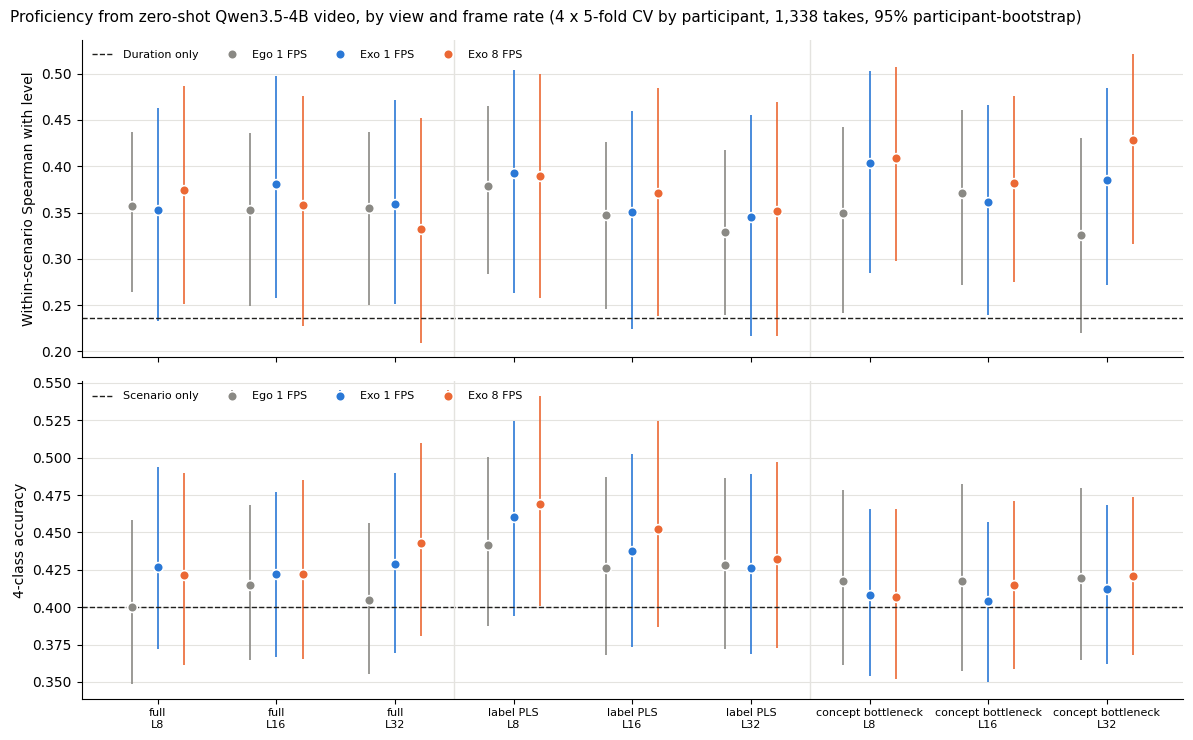

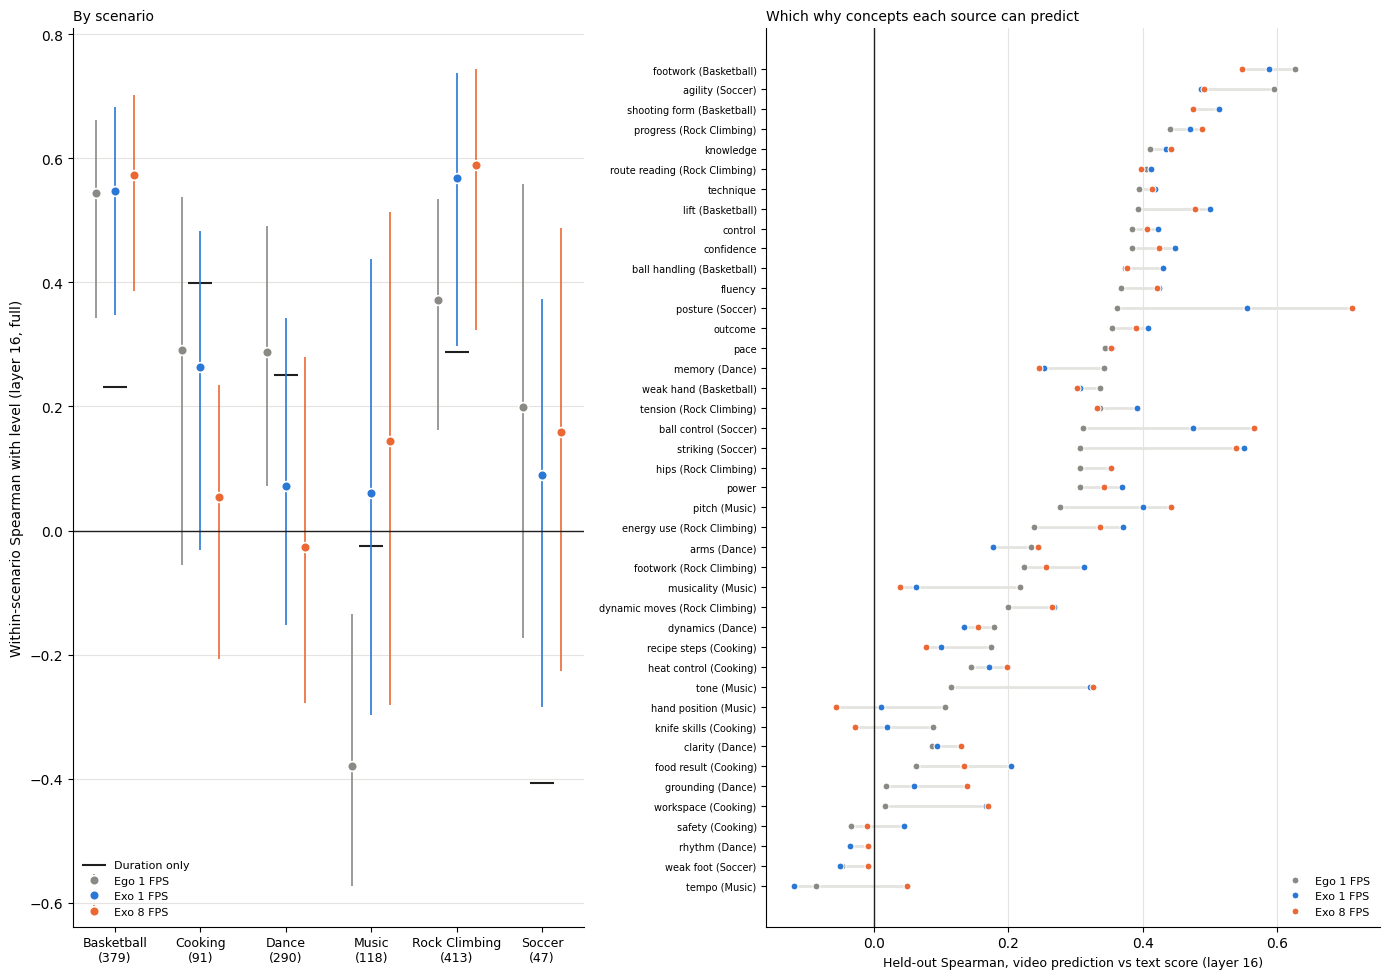

In [10]:
import matplotlib.pyplot as plt

SOURCE_COLORS = {"ego 1 FPS": "#8a8984", "exo 1 FPS": "#2a78d6", "exo 8 FPS": "#eb6834"}
GRID_COLOR, DARK = "#e4e3df", "#1f1f1d"

def style(ax, axis="y"):
    ax.grid(axis=axis, color=GRID_COLOR, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

def dots(ax, x, values, color, label=None):
    values = np.asarray(values)
    ax.errorbar(x, values[:, 0], yerr=[values[:, 0] - values[:, 1], values[:, 2] - values[:, 0]], ls="none", marker="o",
                ms=7, color=color, markeredgecolor="white", markeredgewidth=1.2, elinewidth=1.2, capsize=0, label=label)

# Figure 1: accuracy and ordinal Spearman for every method and layer, by source.
groups = [(m, l) for m in METHODS for l in LAYER_LIST]
x = np.arange(len(groups))
offsets = dict(zip(SOURCE_NAMES, (-0.22, 0, 0.22)))
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
for ax, index, baseline, ylabel in ((axes[0], 1, "duration only", "Within-scenario Spearman with level"),
                                    (axes[1], 0, "scenario only", "4-class accuracy")):
    for source in SOURCE_NAMES:
        dots(ax, x + offsets[source], [stats[f"{source}, L{l}: {m}", "All"][index] for m, l in groups],
             SOURCE_COLORS[source], source[0].upper() + source[1:])
    ax.axhline(stats[baseline, "All"][index][0], color=DARK, lw=1, ls="--", label=baseline.capitalize())
    ax.set_ylabel(ylabel)
    style(ax)
for k in range(1, len(METHODS)):
    for ax in axes:
        ax.axvline(k * len(LAYER_LIST) - 0.5, color=GRID_COLOR, lw=1)
axes[1].set_xticks(x, [f"{m}\nL{l}" for m, l in groups], fontsize=8)
axes[0].legend(frameon=False, fontsize=8, ncol=4, loc="upper left")
axes[1].legend(frameon=False, fontsize=8, ncol=4, loc="upper left")
fig.suptitle(f"Proficiency from zero-shot Qwen3.5-4B video, by view and frame rate ({N_REPEATS} x {N_FOLDS}-fold CV by "
             "participant, 1,338 takes, 95% participant-bootstrap)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig("figures/exo_8fps_proficiency.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 2: per-scenario Spearman (layer 16, full features) and concept visibility by source.
fig, (ax, ax_vis) = plt.subplots(1, 2, figsize=(14, 0.2 * len(COLUMNS) + 1.5), gridspec_kw={"width_ratios": [1, 1.2]})
xs = np.arange(len(SCENARIO_NAMES))
for source in SOURCE_NAMES:
    dots(ax, xs + offsets[source], [by_scenario[f"{source}, L16: full"][s] for s in SCENARIO_NAMES], SOURCE_COLORS[source],
         source[0].upper() + source[1:])
ax.scatter(xs, [by_scenario["duration only"][s][0] for s in SCENARIO_NAMES], marker="_", s=300, color=DARK, label="Duration only")
ax.axhline(0, color=DARK, lw=1)
ax.set_xticks(xs, [f"{s}\n({(scenarios == s).sum()})" for s in SCENARIO_NAMES], fontsize=9)
ax.set_ylabel("Within-scenario Spearman with level (layer 16, full)")
ax.set_title("By scenario", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower left")
style(ax)
y = np.arange(len(COLUMNS))[::-1]
for source in SOURCE_NAMES:
    values = np.array([visibility[source, c][0] for c in order])
    ax_vis.plot(values, y, "o", color=SOURCE_COLORS[source], ms=5, markeredgecolor="white", markeredgewidth=0.8,
                label=source[0].upper() + source[1:])
for row, column in zip(y, order):
    values = [visibility[s, column][0] for s in SOURCE_NAMES]
    ax_vis.plot([min(values), max(values)], [row, row], color=GRID_COLOR, lw=2, zorder=0)
ax_vis.set_yticks(y, [COLUMNS[c][1] + ("" if COLUMNS[c][0] == "all" else f" ({COLUMNS[c][0]})") for c in order], fontsize=7)
ax_vis.axvline(0, color=DARK, lw=1)
ax_vis.set_xlabel(f"Held-out Spearman, video prediction vs text score (layer {VIS_LAYER})", fontsize=9)
ax_vis.set_title("Which why concepts each source can predict", loc="left", fontsize=10)
ax_vis.legend(frameon=False, fontsize=8, loc="lower right")
style(ax_vis, "x")
fig.tight_layout()
fig.savefig("figures/exo_8fps_scenarios_concepts.png", dpi=200, bbox_inches="tight")
plt.show()